# Diwali Sales Data Analysis
Exploratory Data Analysis (EDA) of festive retail sales data to uncover customer demographics, regional trends, and top-performing product categories.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("Diwali Sales Data.csv", encoding='unicode_escape')

In [3]:
df.head()

,User_ID,Cust_name,Product_ID,Gender,Age Group,Age,Marital_Status,State,Zone,Occupation,Product_Category,Orders,Amount,Status,unnamed1
0,1002903,Sanskriti,P00125942,F,26-35,28,0,Maharashtra,Western,Healthcare,Auto,1,23952.0,NaN,NaN
1,1000732,Kartik,P00110942,F,26-35,35,1,Andhra Pradesh,Southern,Govt,Auto,3,23934.0,NaN,NaN
2,1001990,Bindu,P00118542,F,26-35,35,1,Uttar Pradesh,Central,Automobile,Auto,3,23924.0,NaN,NaN
3,1001425,Sudevi,P00237842,M,0-17,16,0,Karnataka,Southern,Construction,Auto,2,23912.0,NaN,NaN
4,1000588,Joni,P00057942,M,26-35,28,1,Gujarat,Western,Food Processing,Auto,2,23877.0,NaN,NaN


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11251 entries, 0 to 11250
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   User_ID           11251 non-null  int64  
 1   Cust_name         11251 non-null  object 
 2   Product_ID        11251 non-null  object 
 3   Gender            11251 non-null  object 
 4   Age Group         11251 non-null  object 
 5   Age               11251 non-null  int64  
 6   Marital_Status    11251 non-null  int64  
 7   State             11251 non-null  object 
 8   Zone              11251 non-null  object 
 9   Occupation        11251 non-null  object 
 10  Product_Category  11251 non-null  object 
 11  Orders            11251 non-null  int64  
 12  Amount            11239 non-null  float64
 13  Status            0 non-null      float64
 14  unnamed1          0 non-null      float64
dtypes: float64(3), int64(4), object(8)
memory usage: 1.3+ MB


In [6]:
#droping blank columns
df.drop(['Status','unnamed1'],axis=1,inplace=True)

In [8]:
pd.isnull(df).sum()

User_ID              0
Cust_name            0
Product_ID           0
Gender               0
Age Group            0
Age                  0
Marital_Status       0
State                0
Zone                 0
Occupation           0
Product_Category     0
Orders               0
Amount              12
dtype: int64

In [10]:
#it shows dimensions of a DataFrame, means rows and columns. 
df.shape

(11251, 13)

In [11]:
df.dropna(inplace=True)

In [12]:
df.shape

(11239, 13)

In [19]:
#change the datatype incase we want whole number rather than float(decimal)
df['Amount']=df['Amount'].astype('int')

In [20]:
df['Amount'].dtype

dtype('int64')

In [18]:
df.columns

Index(['User_ID', 'Cust_name', 'Product_ID', 'Gender', 'Age Group', 'Age',
       'Marital_Status', 'State', 'Zone', 'Occupation', 'Product_Category',
       'Orders', 'Amount'],
      dtype='object')

In [22]:
df.describe()

,User_ID,Age,Marital_Status,Orders,Amount
count,1.123900e+04,11239.000000,11239.000000,11239.000000,11239.000000
mean,1.003004e+06,35.410357,0.420055,2.489634,9453.610553
std,1.716039e+03,12.753866,0.493589,1.114967,5222.355168
min,1.000001e+06,12.000000,0.000000,1.000000,188.000000
25%,1.001492e+06,27.000000,0.000000,2.000000,5443.000000
50%,1.003064e+06,33.000000,0.000000,2.000000,8109.000000
75%,1.004426e+06,43.000000,1.000000,3.000000,12675.000000
max,1.006040e+06,92.000000,1.000000,4.000000,23952.000000


In [23]:
#describe function on specific columns.
df[['Age','Orders','Amount']].describe()

,Age,Orders,Amount
count,11239.000000,11239.000000,11239.000000
mean,35.410357,2.489634,9453.610553
std,12.753866,1.114967,5222.355168
min,12.000000,1.000000,188.000000
25%,27.000000,2.000000,5443.000000
50%,33.000000,2.000000,8109.000000
75%,43.000000,3.000000,12675.000000
max,92.000000,4.000000,23952.000000


## Exploratory Data Analysis

### 1. Gender

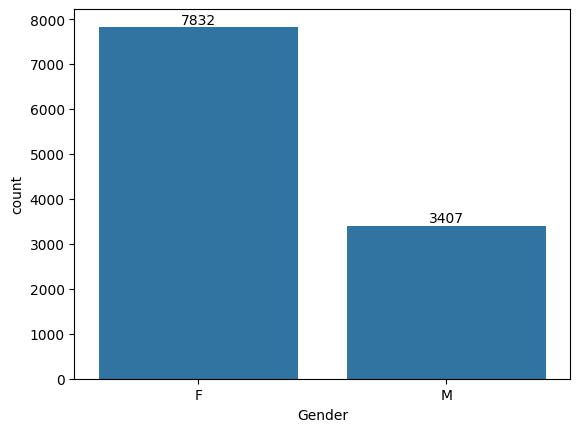

In [27]:
ax=sns.countplot(x='Gender',data=df)
for bars in ax.containers:
    ax.bar_label(bars)

<Axes: xlabel='Gender', ylabel='Amount'>

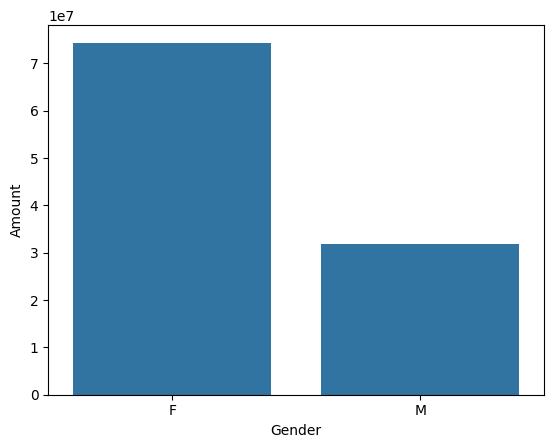

In [28]:
sales_gen=df.groupby(['Gender'],as_index=False)['Amount'].sum().sort_values(by='Amount',ascending=False)
sns.barplot(x='Gender',y='Amount',data=sales_gen)

*From the above graphs, we can see that most of the buyers are females and the purchasing power of females is greater than males.*

### 2. Age

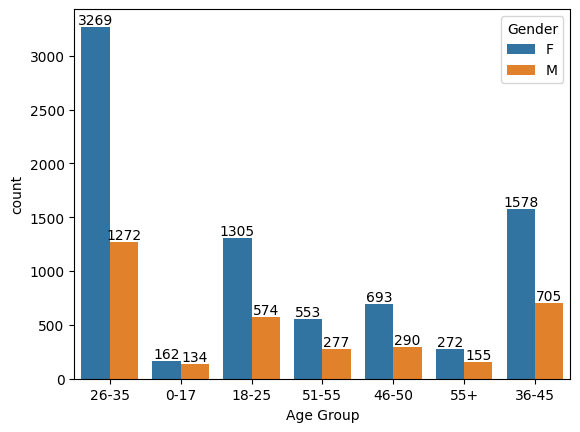

In [29]:
ax=sns.countplot(x='Age Group',data=df,hue='Gender')
for bars in ax.containers:
    ax.bar_label(bars)

<Axes: xlabel='Age Group', ylabel='Amount'>

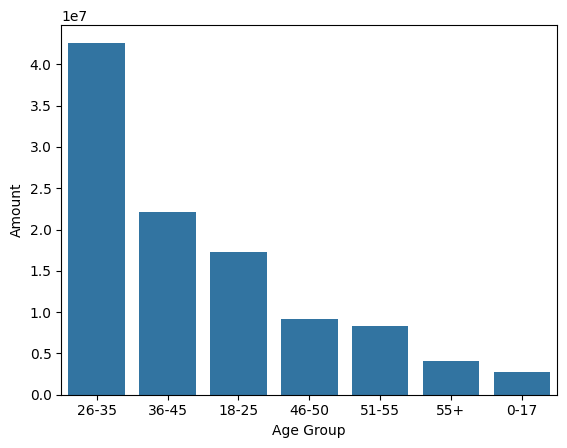

In [36]:
#By amount
sales_age=df.groupby(['Age Group'],as_index=False)['Amount'].sum().sort_values(by='Amount',ascending=False)
sns.barplot(x='Age Group',y='Amount',data=sales_age)

*From the above graphs, we can see that most of the buyers are females in the 26–35 years age group.*

### 3. State

<Axes: xlabel='State', ylabel='Orders'>

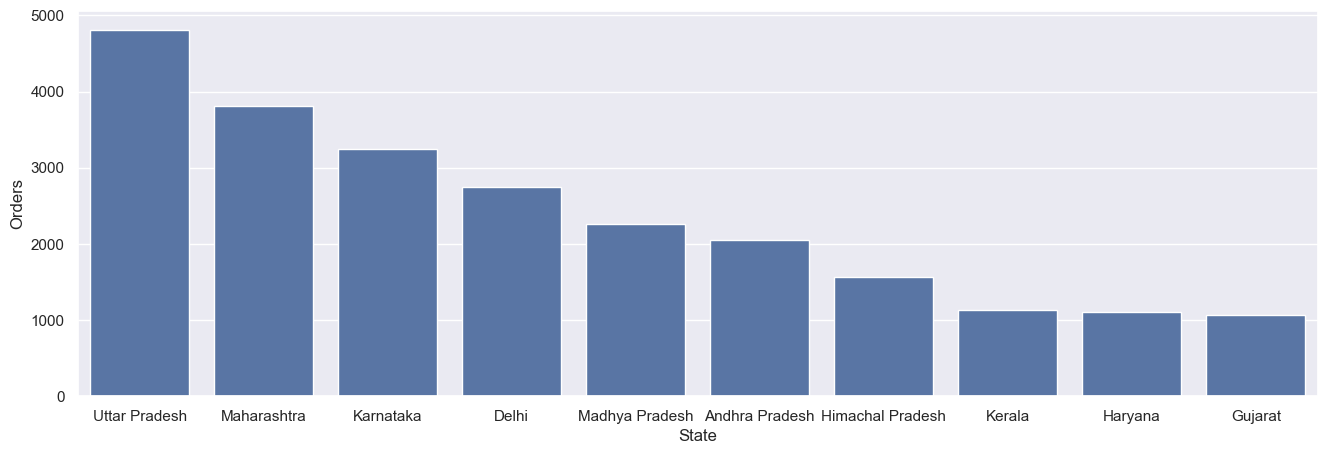

In [4]:
#total number of orders from top 10 States

sales_states=df.groupby(['State'],as_index=False)['Orders'].sum().sort_values(by='Orders',ascending=False).head(10)
sns.set(rc={'figure.figsize':(16,5)})
sns.barplot(data=sales_states,x='State',y='Orders')
#plt.xticks(rotation=45)

<Axes: xlabel='State', ylabel='Amount'>

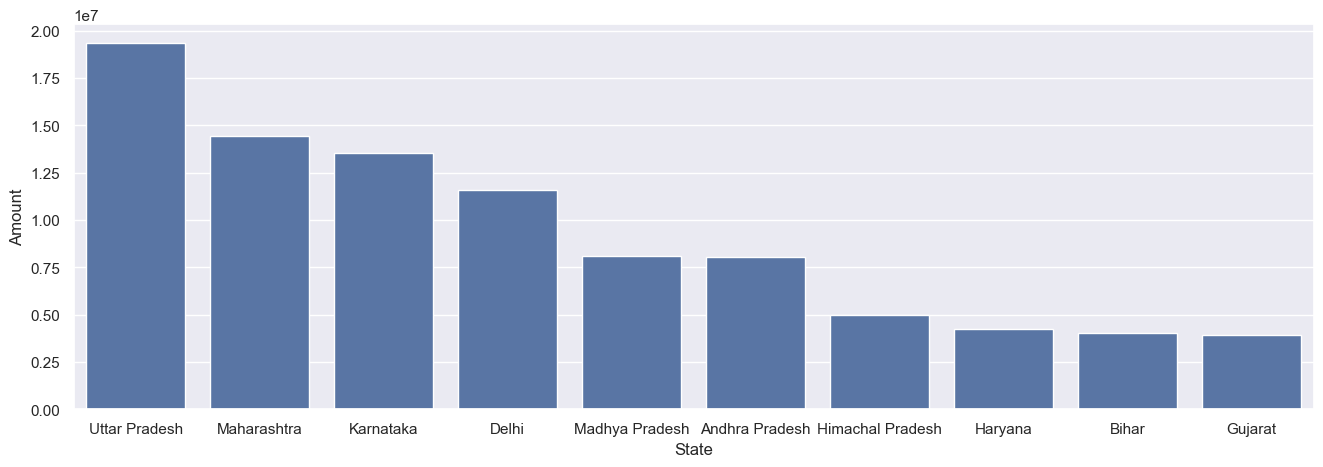

In [5]:
#total amount / sales from top 5 states.
state_am=df.groupby(['State'],as_index=False)['Amount'].sum().sort_values(by='Amount',ascending=False).head(10)
sns.set(rc={'figure.figsize':(16,5)})
sns.barplot(data=state_am,x='State',y='Amount')

*From the above figures, we can see that most of the orders and total sales come from Uttar Pradesh, Maharashtra, and Karnataka respectively.*

### 4. Marital Status

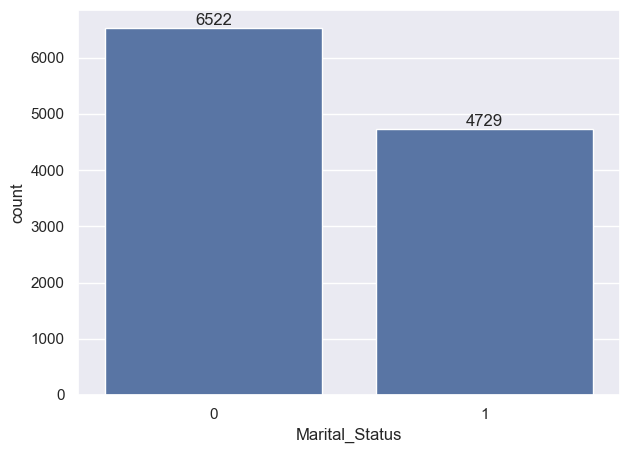

In [8]:
ax=sns.countplot(data=df,x='Marital_Status')
sns.set(rc={'figure.figsize':(7,4)})
for bars in ax.containers:
    ax.bar_label(bars)

<Axes: xlabel='Marital_Status', ylabel='Amount'>

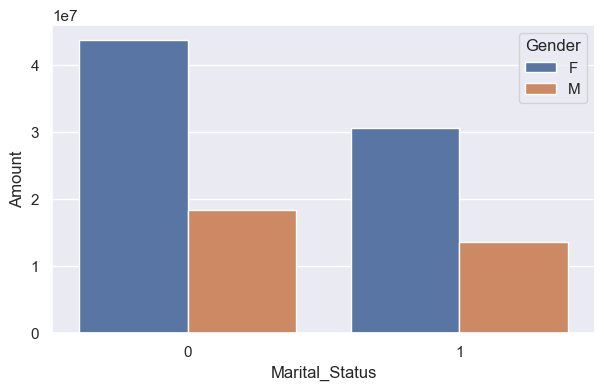

In [11]:
#by amount
marital_s=df.groupby(['Marital_Status','Gender'],as_index=False)['Amount'].sum().sort_values(by='Amount',ascending=False)
sns.barplot(data=marital_s,x='Marital_Status',y='Amount',hue='Gender')

*From the above graphs, we can see that most of the buyers are unmarried (0) women and they have higher purchasing power.*

### 5. Occupation

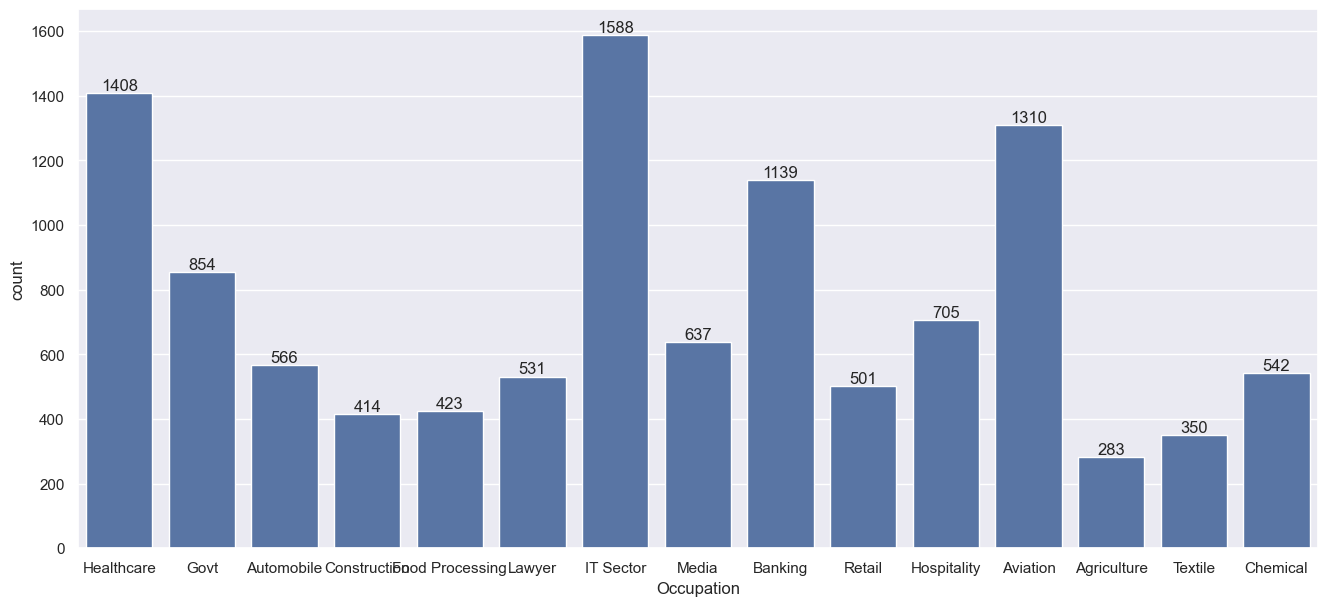

In [17]:
ax=sns.countplot(data=df,x='Occupation')
sns.set(rc={'figure.figsize':(16,7)})
for bars in ax.containers:
    ax.bar_label(bars)

<Axes: xlabel='Occupation', ylabel='Amount'>

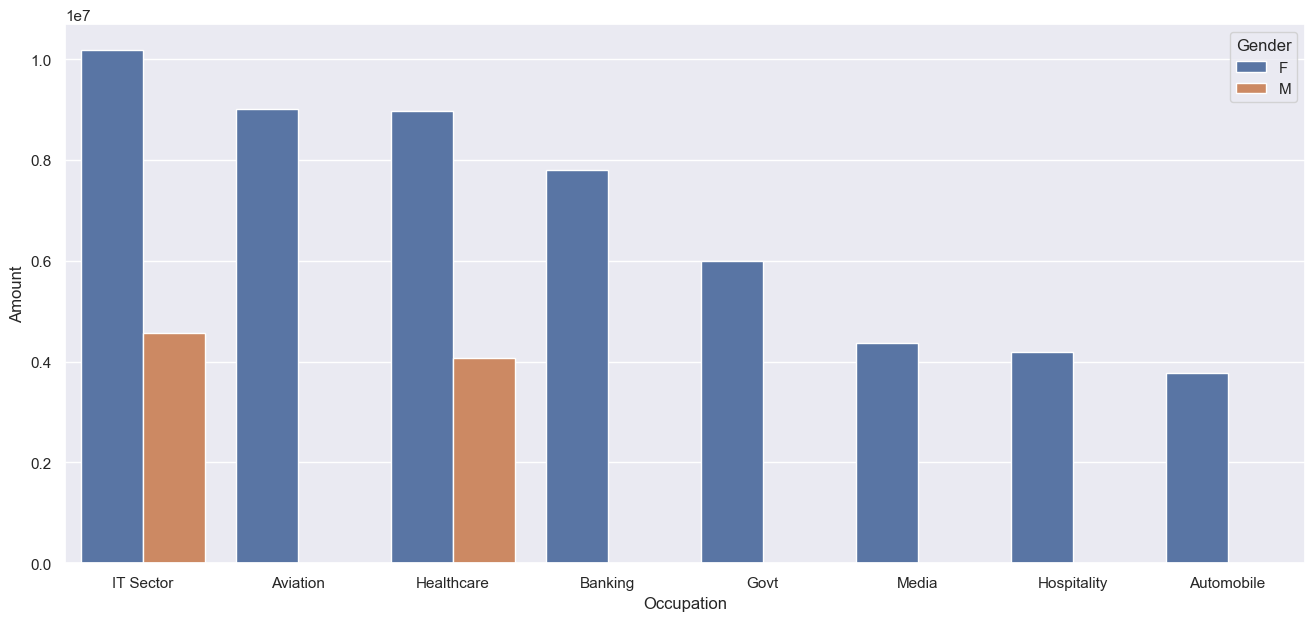

In [19]:
#by amount
o_s=df.groupby(['Occupation','Gender'],as_index=False)['Amount'].sum().sort_values(by='Amount',ascending=False).head(10)
sns.barplot(data=o_s,x='Occupation',y='Amount',hue='Gender')

*From the above graphs, we can see that most of the buyers work in the IT, Aviation, and Healthcare sectors.*

### 6. Product Category

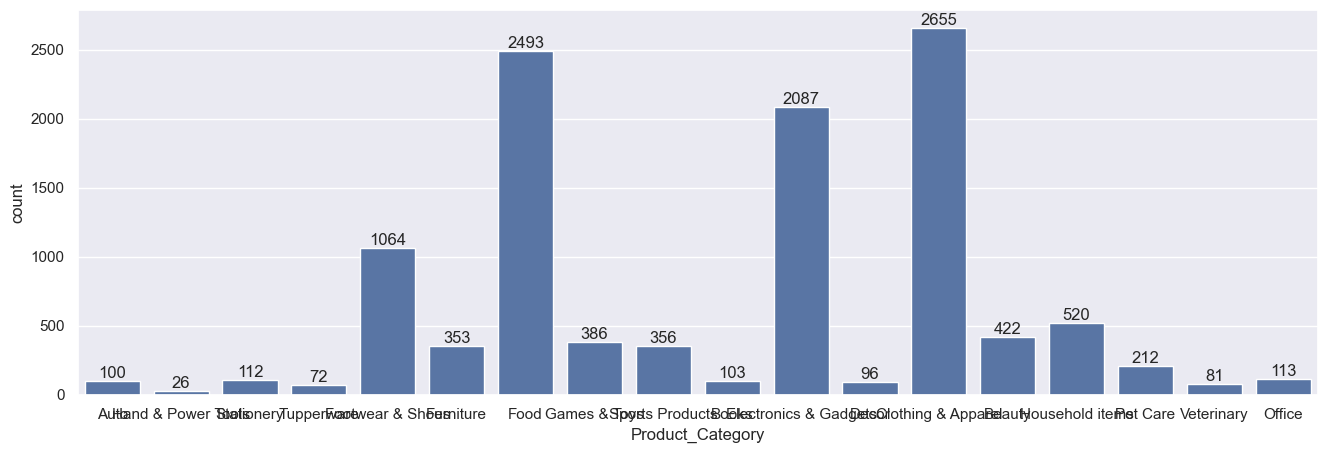

In [23]:
ax=sns.countplot(data=df,x='Product_Category')
sns.set(rc={'figure.figsize':(25,5)})
for bars in ax.containers:
    ax.bar_label(bars)

<Axes: xlabel='Product_Category', ylabel='Amount'>

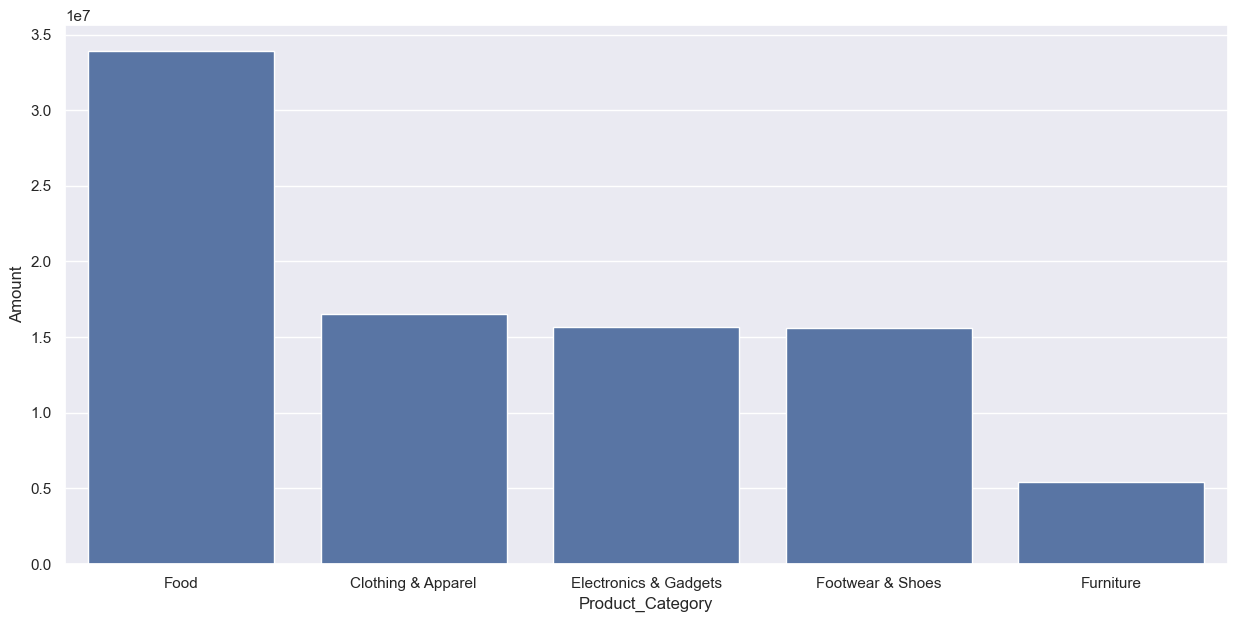

In [28]:
#by amount
p_c=df.groupby(['Product_Category'],as_index=False)['Amount'].sum().sort_values(by='Amount',ascending=False).head(5)
sns.set(rc={'figure.figsize':(15,7)})
sns.barplot(data=p_c,x='Product_Category',y='Amount')

*From the above graphs, we can see that most of the sold products are from Food, Clothing & Apparel, and Electronics & Gadgets.*

<Axes: xlabel='Product_ID', ylabel='Orders'>

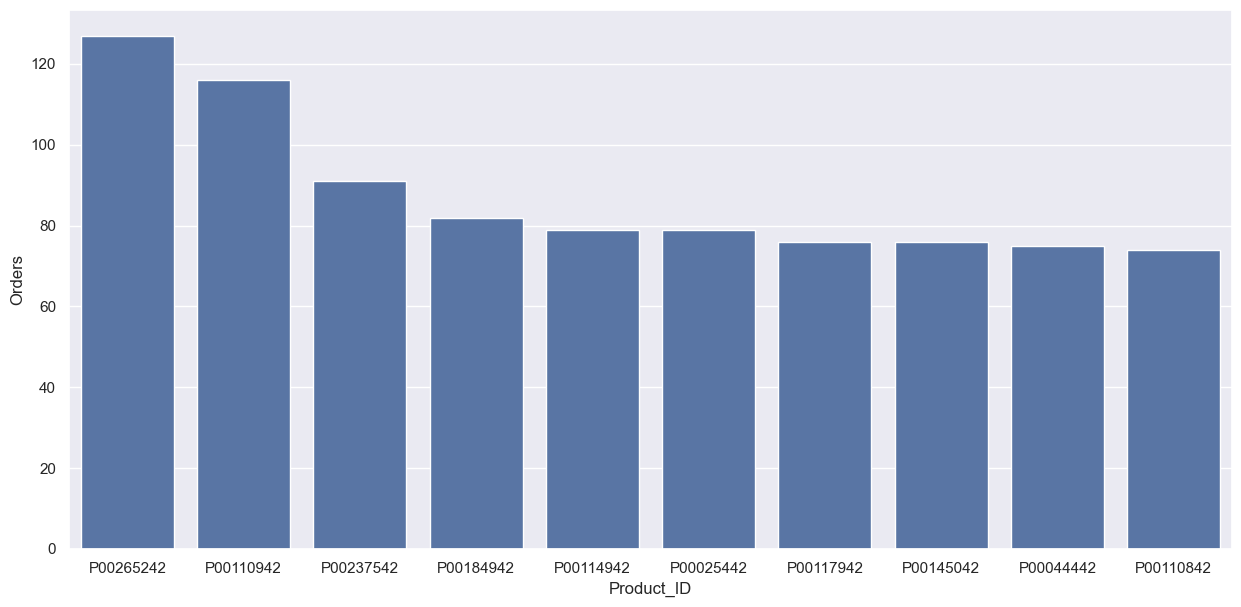

In [31]:
#Checking top selling products by the product id
p_i=df.groupby(['Product_ID'],as_index=False)['Orders'].sum().sort_values(by='Orders',ascending=False).head(10)
sns.barplot(data=p_i,x='Product_ID',y='Orders')

## Conclusion
Unmarried women in the **26–35 years** age group from **Uttar Pradesh, Maharashtra, and Karnataka** working in the **IT, Healthcare, and Aviation** sectors are more likely to buy products from the **Food, Clothing, and Electronics** categories.